# Exploratory Data Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt,seaborn as sns
%matplotlib inline

In [2]:
df=pd.read_csv("data/resumes.csv")
df

,label,text
0,Data Science,Skills * Programming Languages: Python (pandas...
1,Data Science,Education Details \nMay 2013 to May 2017 B.E ...
2,Data Science,"Areas of Interest Deep Learning, Control Syste..."
3,Data Science,Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4,Data Science,"Education Details \n MCA YMCAUST, Faridabad..."
...,...,...
957,Testing,Computer Skills: â¢ Proficient in MS office (...
958,Testing,â Willingness to accept the challenges. â ...
959,Testing,"PERSONAL SKILLS â¢ Quick learner, â¢ Eagerne..."
960,Testing,COMPUTER SKILLS & SOFTWARE KNOWLEDGE MS-Power ...


In [3]:
df=df.dropna()
df=df[df["text"].astype(str).str.strip() != " "]
df

,label,text
0,Data Science,Skills * Programming Languages: Python (pandas...
1,Data Science,Education Details \nMay 2013 to May 2017 B.E ...
2,Data Science,"Areas of Interest Deep Learning, Control Syste..."
3,Data Science,Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4,Data Science,"Education Details \n MCA YMCAUST, Faridabad..."
...,...,...
957,Testing,Computer Skills: â¢ Proficient in MS office (...
958,Testing,â Willingness to accept the challenges. â ...
959,Testing,"PERSONAL SKILLS â¢ Quick learner, â¢ Eagerne..."
960,Testing,COMPUTER SKILLS & SOFTWARE KNOWLEDGE MS-Power ...


## Distribution

In [4]:
sns.set_theme(style="whitegrid")

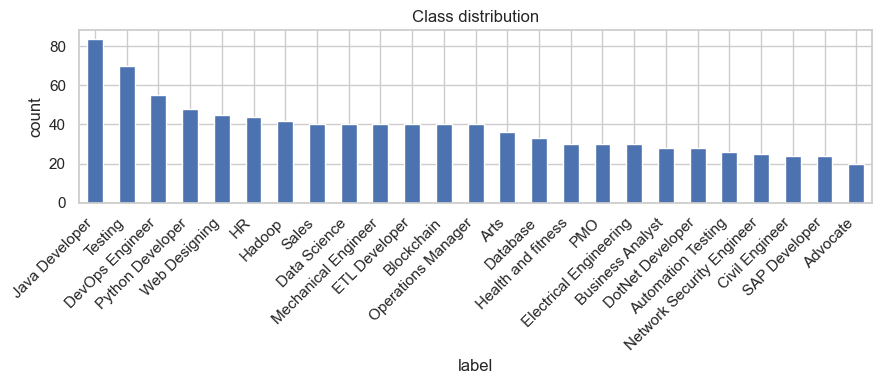

In [5]:
counts=df["label"].value_counts()
fig,ax=plt.subplots(figsize=(9,4))
counts.plot(kind='bar',ax=ax)
ax.set_title('Class distribution') 
ax.set_ylabel('count')
plt.xticks(rotation=45,ha='right') 
plt.tight_layout() 
plt.show()

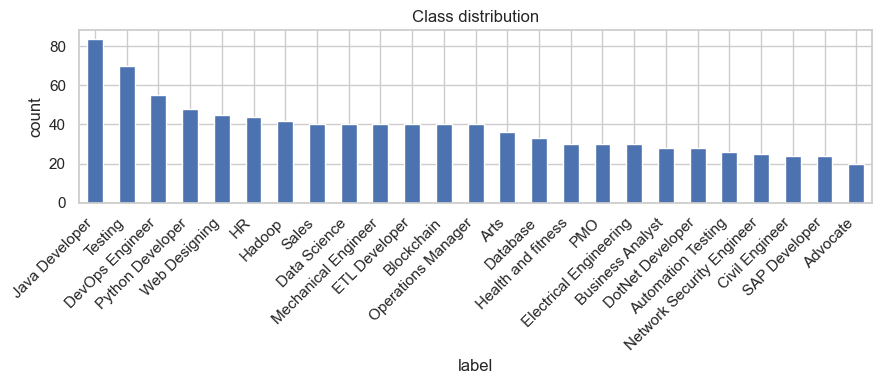

In [6]:
fig,ax=plt.subplots(figsize=(9,4))
counts.plot(kind='bar',ax=ax,color='#4c72b0'); ax.set_title('Class distribution'); ax.set_ylabel('count')
plt.xticks(rotation=45,ha='right'); plt.tight_layout(); plt.show()

In [7]:
print(counts.to_string())

label
Java Developer               84
Testing                      70
DevOps Engineer              55
Python Developer             48
Web Designing                45
HR                           44
Hadoop                       42
Sales                        40
Data Science                 40
Mechanical Engineer          40
ETL Developer                40
Blockchain                   40
Operations Manager           40
Arts                         36
Database                     33
Health and fitness           30
PMO                          30
Electrical Engineering       30
Business Analyst             28
DotNet Developer             28
Automation Testing           26
Network Security Engineer    25
Civil Engineer               24
SAP Developer                24
Advocate                     20


In [8]:
## text length per class

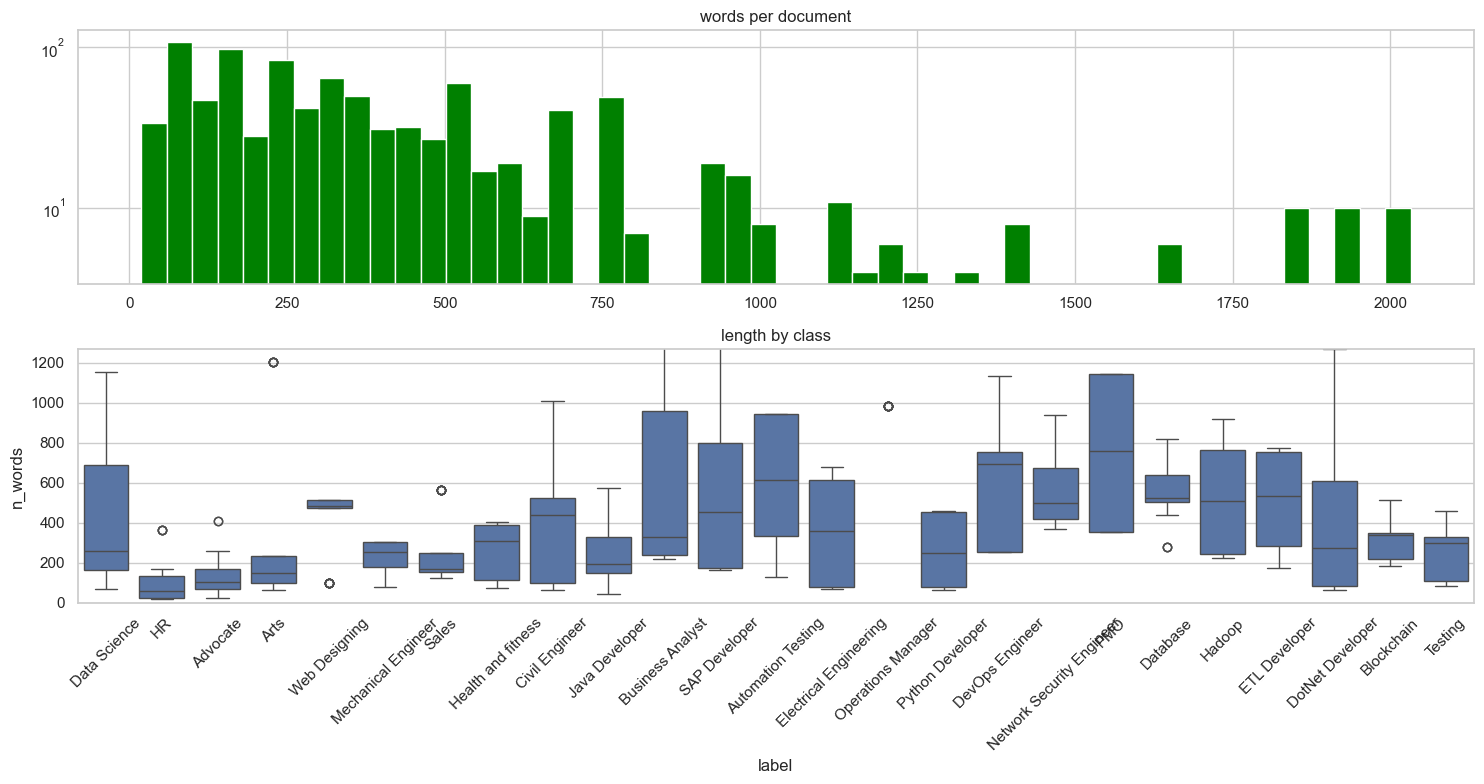

words median 329, max 2209


In [9]:
df['n_words']=df['text'].astype(str).str.split().apply(len)
fig,ax=plt.subplots(2,figsize=(15,8))
ax[0].hist(df['n_words'].clip(upper=df['n_words'].quantile(0.99)),bins=50,color='green')
ax[0].set_title('words per document')
ax[0].set_yscale('log')
sns.boxplot(x='label',y='n_words',data=df,ax=ax[1])
ax[1].set_ylim(0,df['n_words'].quantile(0.95))
ax[1].set_title('length by class')
ax[1].tick_params(axis='x',rotation=45)
plt.tight_layout()
plt.show()
print('words median %d, max %d'%(df['n_words'].median(),df['n_words'].max()))

## top words

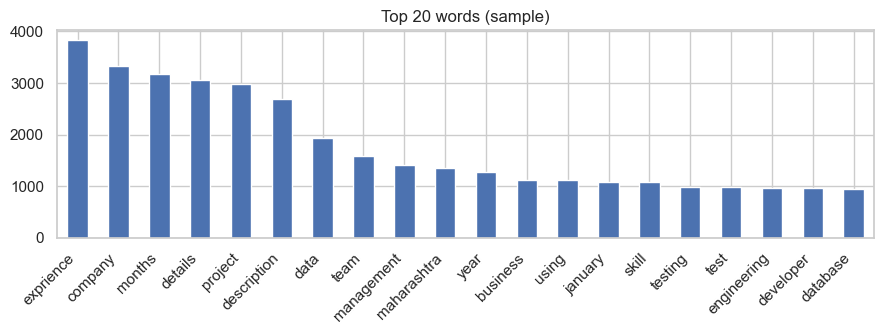

In [11]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
words=Counter()
for i in df['text'].astype(str).head(3000):
    words.update(w for w in i.lower().split() if w.isalpha() and w not in ENGLISH_STOP_WORDS and len(w)>2)
top=pd.Series(dict(words.most_common(20)))
fig,ax=plt.subplots(figsize=(9,3.5))
top.plot(kind='bar',ax=ax)
ax.set_title('Top 20 words (sample)')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

In [12]:
for lab in df['label'].unique()[:6]:
    s=df[df['label']==lab]['text'].iloc[0]
    print(f'[{lab}] '+str(s)[:160].replace(chr(10),' ')+'...\n')

[Data Science] Skills * Programming Languages: Python (pandas, numpy, scipy, scikit-learn, matplotlib), Sql, Java, JavaScript/JQuery. * Machine learning: Regression, SVM, NaÃ¯...

[HR] TECHNICAL SKILLS â¢ Typewriting â¢ TORA â¢ SPSSEducation Details  January 2017 MBA  Chidambaram, Tamil Nadu SNS College of Engineering January 2014 HSC   at ...

[Advocate] TECHNICAL QUALIFICATIONS: â¢ Windows, Ms. OfficeEducation Details   LL.B  Guwahati, Assam University Law College, Guwahati University  B.Sc  Jagiroad, ASSAM, I...

[Arts] â¢ Good communication skill â¢ Quick learner â¢ Keen to find solutionsEducation Details   MBA Marketing and International Business Management Pune, Maharasht...

[Web Designing] Technical Skills Web Technologies: Angular JS, HTML5, CSS3, SASS, Bootstrap, Jquery, Javascript. Software: Brackets, Visual Studio, Photoshop, Visual Studio Cod...

[Mechanical Engineer] Education Details  May 1999 to September 2002 Diploma Mechanical Engg Mumbai, Maharashtra Institute

### Conclusion :
the text need cleaning